In [1]:
!pip install -q "transformers==4.49.0" "tokenizers<0.22" accelerate

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 73.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 91.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 24.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.27.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
!pip install -q "transformers==4.49.0" "tokenizers<0.22" accelerate

In [4]:
!pip install -q transformers

In [5]:
import torch
from PIL import Image
from transformers import BlipProcessor, BlipForConditionalGeneration

device = "cuda" if torch.cuda.is_available() else "cpu"

blip_processor = BlipProcessor.from_pretrained(
    "Salesforce/blip-image-captioning-base"
)

blip_model = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base"
).to(device)

print("BLIP loaded successfully!")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

BLIP loaded successfully!


In [15]:
import os
import json

os.environ['KAGGLE_USERNAME'] = "chandramoulibandaru"
os.environ['KAGGLE_KEY'] = "KGAT_4eed677cb21afe63d661c7c029b2a68a"

os.makedirs('/root/.kaggle', exist_ok=True)
with open('/root/.kaggle/kaggle.json', 'w') as f:
    json.dump({"username": "chandramoulibandaru", "key": "KGAT_4eed677cb21afe63d661c7c029b2a68a"}, f)

os.chmod('/root/.kaggle/kaggle.json', 0o600)





In [17]:
!kaggle datasets download karagwaanntreasure/plant-disease-detection


Dataset URL: https://www.kaggle.com/datasets/karagwaanntreasure/plant-disease-detection
License(s): MIT
100% 534M/534M [00:08<00:00, 66.9MB/s]



In [18]:
import zipfile
zip=zipfile.ZipFile('/content/plant-disease-detection.zip','r')
zip.extractall()
zip.close()

In [19]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.layers import Dense,Flatten,Dropout,BatchNormalization
from tensorflow.keras.applications import InceptionResNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
import cv2
import keras
import tensorflow

In [20]:

import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121,ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau,ModelCheckpoint
from sklearn.metrics import confusion_matrix
import numpy as np


In [21]:

train_data=keras.utils.image_dataset_from_directory(
    directory='/content/Dataset',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(160,160),
    subset='training',
    validation_split=0.2,
    seed=123,
    shuffle=True
)
validation_data=keras.utils.image_dataset_from_directory(
    directory='/content/Dataset',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(160,160),
    subset='validation',
    validation_split=0.2,
    seed=123,
    shuffle=True
)

Found 35725 files belonging to 23 classes.
Using 28580 files for training.
Found 35725 files belonging to 23 classes.
Using 7145 files for validation.


In [22]:
!pip install -q transformers

In [23]:
import torch
from PIL import Image
from transformers import BlipProcessor, BlipForConditionalGeneration

device = "cuda" if torch.cuda.is_available() else "cpu"

blip_processor = BlipProcessor.from_pretrained(
    "Salesforce/blip-image-captioning-base"
)

blip_model = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base"
).to(device)

print("BLIP loaded successfully!")

BLIP loaded successfully!


In [26]:
images, labels = next(iter(validation_data))

sample_image = images[0].numpy().astype("uint8")
sample_pil = Image.fromarray(sample_image).convert("RGB")

class_names = train_data.class_names
true_class = class_names[labels[0].numpy()]

print("Actual class:", true_class)

Actual class: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot


In [27]:
inputs = blip_processor(
    images=sample_pil,
    return_tensors="pt"
).to(device)

with torch.no_grad():
    output = blip_model.generate(
        **inputs,
        max_new_tokens=50
    )

caption = blip_processor.decode(
    output[0],
    skip_special_tokens=True
)

print("Image Understanding:")
print(caption)

Image Understanding:
a green and brown rock with a small piece of wood


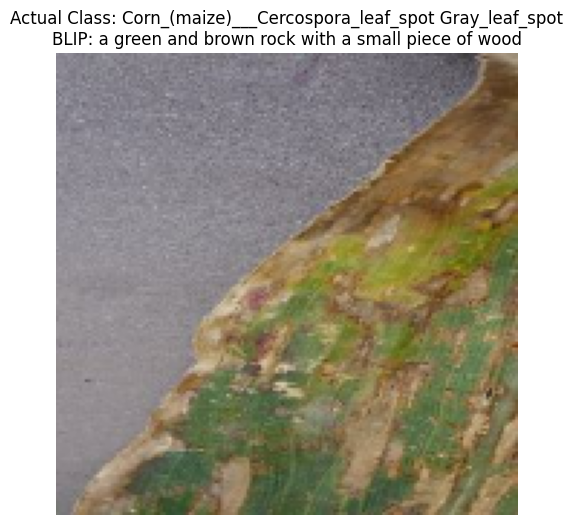

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.imshow(sample_pil)
plt.axis("off")
plt.title(f"Actual Class: {true_class}\nBLIP: {caption}")
plt.show()